# **1.1**

In [ ]:
import random
import numpy as np
import scipy.stats as sps
import math
import statistics as stat
import matplotlib.pyplot as plt


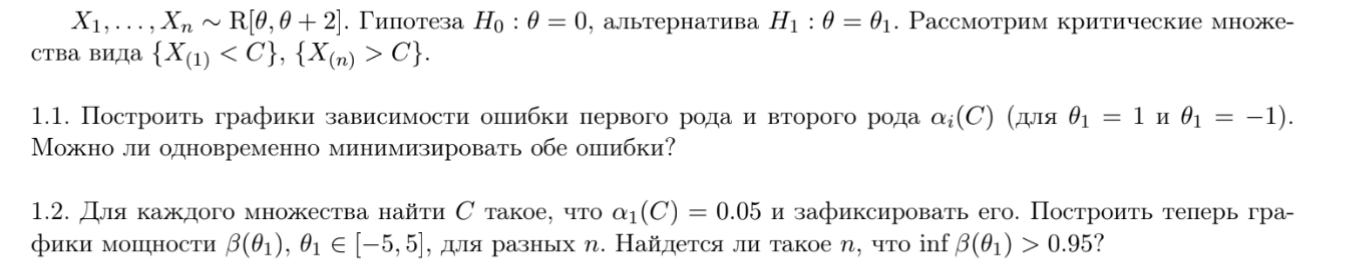

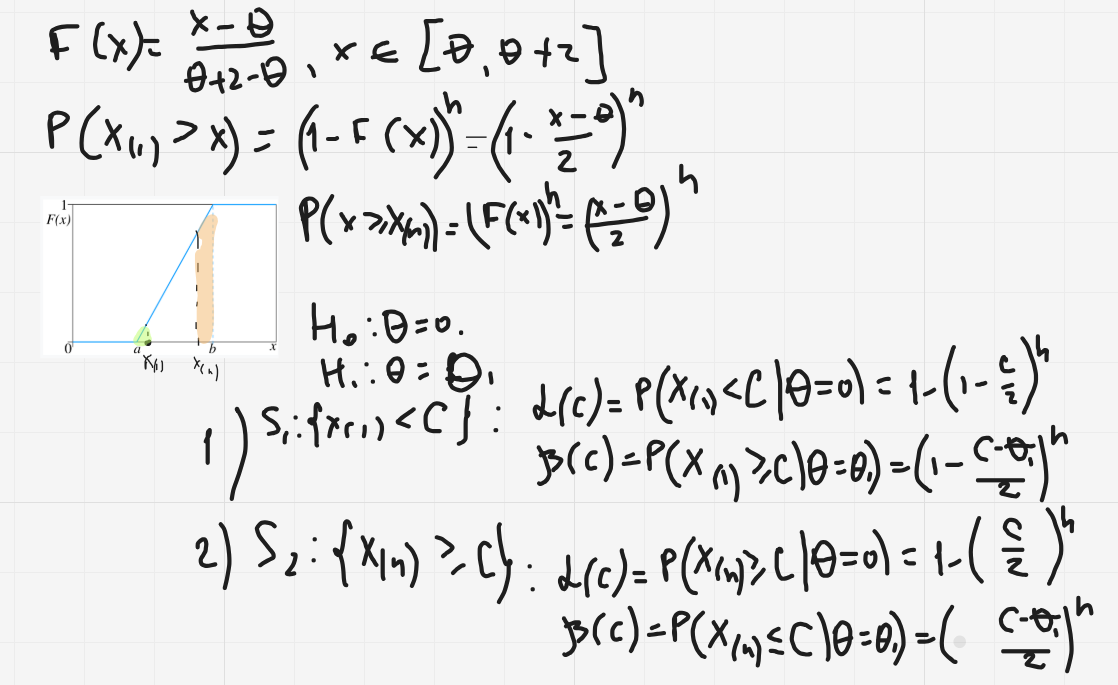

In [ ]:
#theta - неизвестный параметр, для удобства зафиксируем равным 0
theta = 0.
#генерируем выборку
n = 10
uniform_data = np.random.uniform(theta, theta+2, n)
uniform_data

array([1.15544509, 1.42697572, 0.76250463, 0.97881881, 1.92003372,
       1.82445603, 1.63956558, 0.17889975, 1.85265379, 1.22077523])

Для начала посмотрим на критическое множество S2

In [ ]:
#вычислим ошибки 1-го и 2-го рода
def Type_1_Error (C, n):
    return 1.0 - (C / 2.0)**n
def Type_2_Error (C, theta_1, n):
    return ((C - theta_1) / 2.0)**n

In [ ]:
alpha = 0.05
quantile_alpha = sps.uniform(loc=theta, scale=2).ppf(1. - alpha)
C = quantile_alpha/math.sqrt(n) #это можем посчитано аналитически
print ('Значение C(α) для критического множества =', C)

Значение C(α) для критического множества = 0.600832755431992


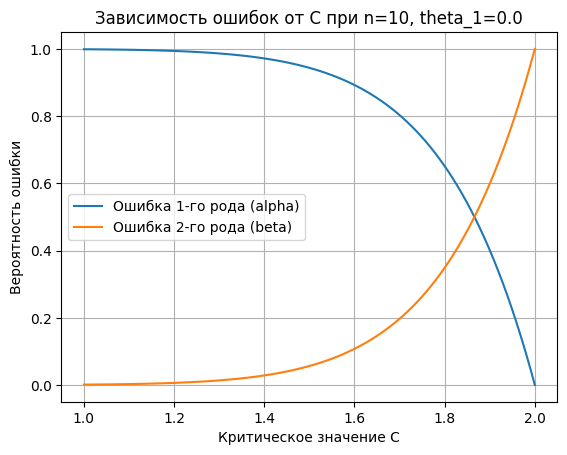

In [ ]:
#размеры выборки, при которых будем смотреть апостериорную плотность
n=10
theta_1 = 0.
# создаём координатную плоскость
fig, ax = plt.subplots()
# создаём область, в которой будет - отображаться график
step = 100
C = np.linspace(1.0, 2.0, step)

alpha = [Type_1_Error(c, n) for c in C]
beta = [Type_2_Error(c, theta_1, n) for c in C]

plt.plot(C, alpha, label='Ошибка 1-го рода (alpha)')
plt.plot(C, beta, label='Ошибка 2-го рода (beta)')
plt.xlabel('Критическое значение C')
plt.ylabel('Вероятность ошибки')
plt.title(f'Зависимость ошибок от C при n={n}, theta_1={theta_1}')
plt.legend()
plt.grid(True)
plt.show()



Оптимизация: нельзя минимизировать обе одновременно, так как они антимонотонны.

# **1.2**

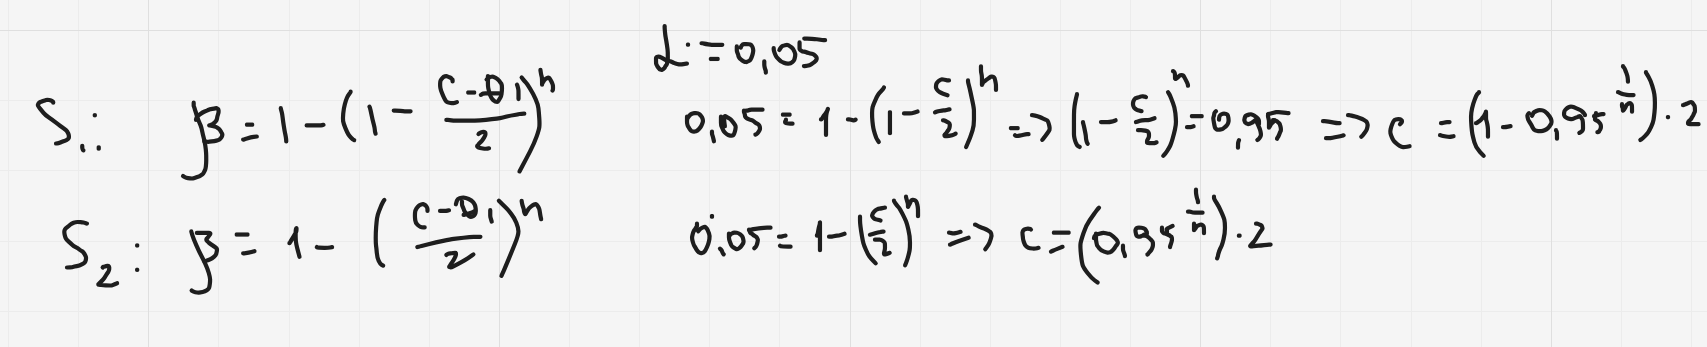

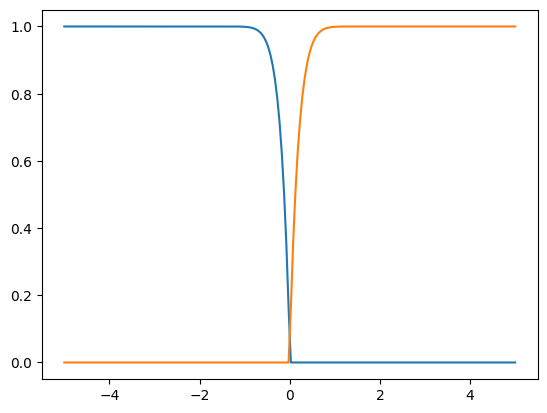

In [ ]:
# Находим C для alpha = 0.05
c1 = 2 * (1 - 0.95**(1/n))
c2 = 2 * (0.95**(1/n))

theta1 = np.linspace(-5, 5, 200)
power1 = 1 - np.clip(1 - (c1 - theta1)/2, 0, 1)**n
power2 = 1 - np.clip((c2 - theta1)/2, 0, 1)**n

plt.plot(theta1, power1, label='Мощность для s1')
plt.plot(theta1, power2, label='Мощность для s2')

Нельзя минимизировать обе ошибки одновременно, так как при фиксированном размере выборки уменьшение области принятия H₀ (для уменьшения ошибки II рода) неизбежно увеличивает область отклонения H₀ (увеличивая ошибку I рода). Для достижения inf β(θ₁) > 0.95 при |θ₁| > δ необходимо увеличивать n, так как с ростом n оценка становится состоятельной.